<a href="https://colab.research.google.com/github/thomas-andromeda/Vision-Computer-2026/blob/main/Praktikum_03_Teknik_Regresi_Gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum D1 – Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)**

**1. Setup & Generator Dataset**

In [61]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models


# Generator 1 sample
def make_sample(img_size=64, min_r=5, max_r=20):
  r = np.random.randint(min_r, max_r + 1)  # radius acak
  img = np.zeros((img_size, img_size), dtype=np.uint8)
  cx = np.random.randint(r, img_size - r)  # center-x
  cy = np.random.randint(r, img_size - r)  # center-y
  cv2.circle(img, (cx, cy), r, (255,), -1)  # lingkaran putih terisi
  img = (img / 255.0).astype(np.float32)
  # 3-channel biar kompatibel CNN
  img3 = np.stack([img, img, img], axis=-1)
  return img3, float(r), (cx, cy)

**2. “Tebak Apa?” — Tampilkan Contoh Gambar TANPA Label**

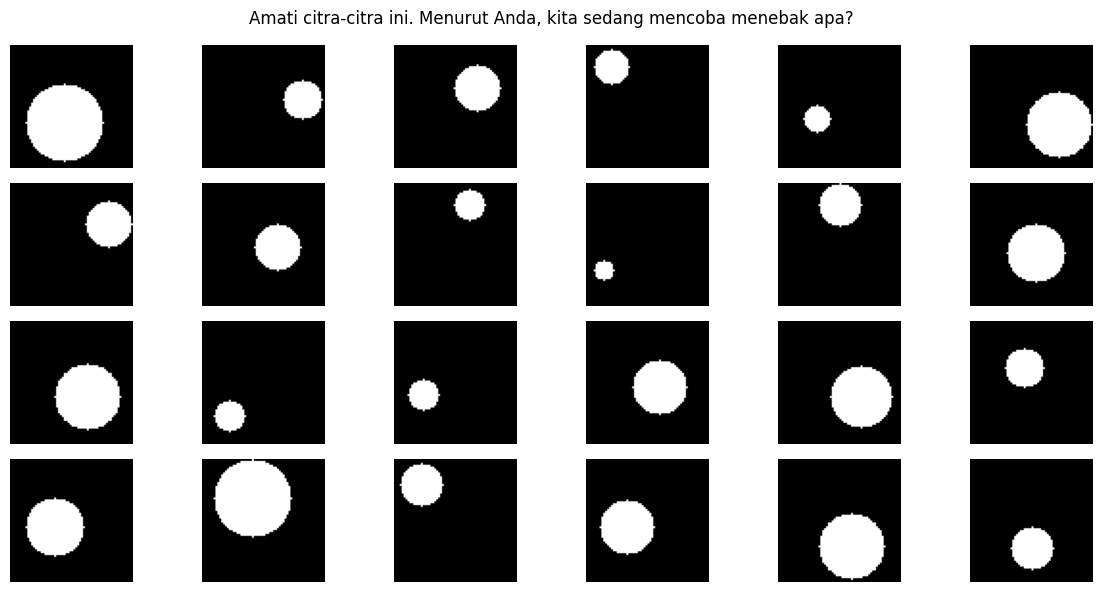

In [62]:
# Buat 24 contoh untuk visualisasi
N_show = 24
samples = [make_sample() for _ in range(N_show)]
imgs = [s[0] for s in samples]
rads = [s[1] for s in samples]
centers = [s[2] for s in samples]

# Grid gambar tanpa label:
cols = 6
rows = N_show // cols
plt.figure(figsize=(12, 6))
for i in range(N_show):
  plt.subplot(rows, cols, i + 1)
  plt.imshow(imgs[i].squeeze(), cmap='gray')
  plt.axis('off')
plt.suptitle(
    'Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?'
)
plt.tight_layout()
plt.show()

**3. Buka Jawaban — Target yang Ingin Diprediksi**

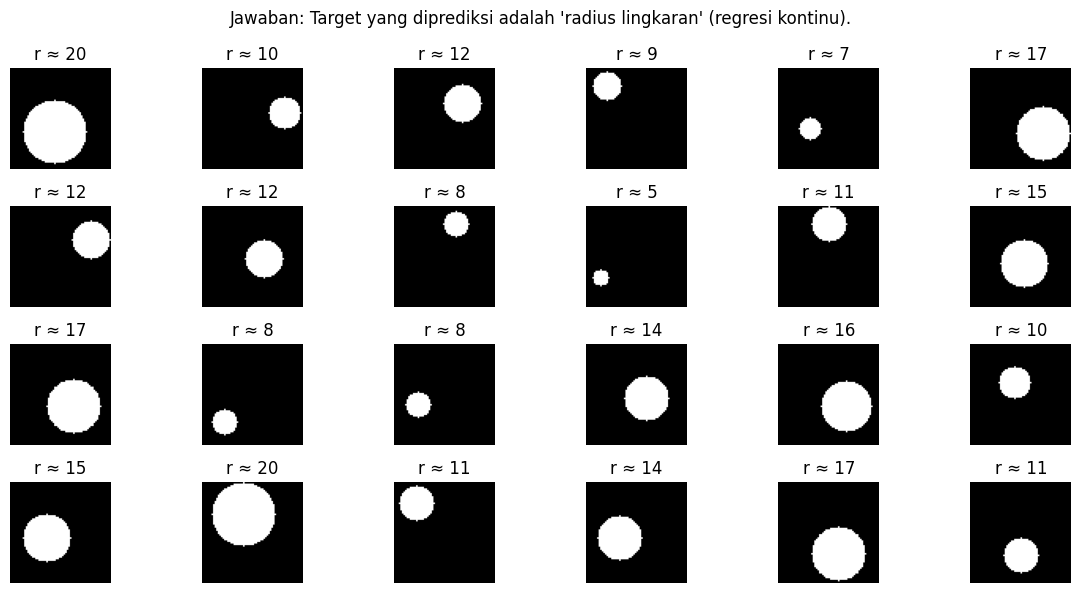

In [63]:
# Tampilkan kembali, sekarang tampilkan radius (label) di judul tiap subplot
plt.figure(figsize=(12, 6))
for i in range(N_show):
  plt.subplot(rows, cols, i + 1)
  plt.imshow(imgs[i].squeeze(), cmap='gray')
  plt.title(f'r ≈ {int(rads[i])}')
  plt.axis('off')
plt.suptitle(
    "Jawaban: Target yang diprediksi adalah 'radius lingkaran' (regresi"
    ' kontinu).'
)
plt.tight_layout()
plt.show()

**4. (Opsional) Latih CNN Kecil untuk Memprediksi Radius**

In [64]:
# Siapkan dataset lebih besar untuk training
N = 3000
X, y, C = zip(*[make_sample() for _ in range(N)])
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# Model CNN sederhana
model = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1),  # output regresi
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
history = model.fit(
    Xtr, ytr, validation_data=(Xte, yte), epochs=12, batch_size=64, verbose=0
)

# Evaluasi
y_pred = model.predict(Xte).ravel()
mae = mean_absolute_error(yte, y_pred)
rmse = float(np.sqrt(np.mean((yte - y_pred) ** 2)))
r2 = r2_score(yte, y_pred)
print(f'MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}')

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
MAE=0.963 | RMSE=1.190 | R²=0.934


**5. Plot history & True vs Predicted**

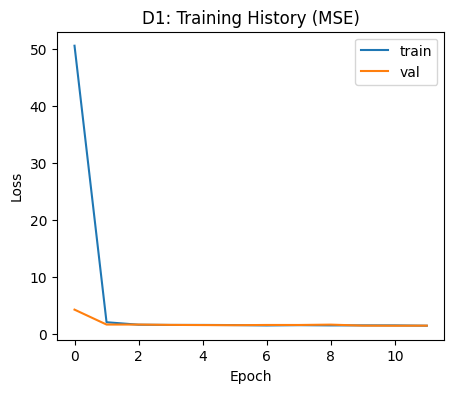

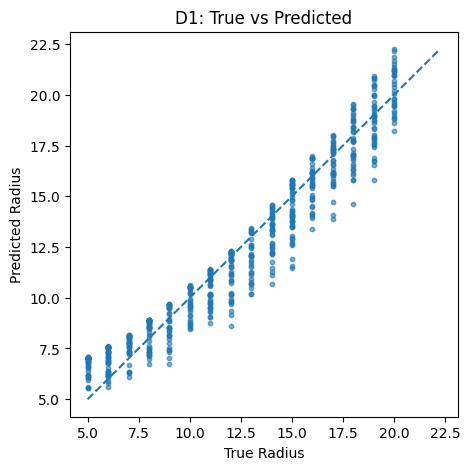

In [65]:
# Plot loss
plt.figure(figsize=(5, 4))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('D1: Training History (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Scatter True vs Pred
plt.figure(figsize=(5, 5))
plt.scatter(yte, y_pred, s=10, alpha=0.6)
lims = [min(yte.min(), y_pred.min()), max(yte.max(), y_pred.max())]
plt.plot(lims, lims, '--')
plt.xlabel('True Radius')
plt.ylabel('Predicted Radius')
plt.title('D1: True vs Predicted')
plt.show()

**TANTANGAN MINI PRAKTIKUM D1**

In [66]:
import cv2
import numpy as np


# Generator dengan rentang radius 8-28 dan Gaussian Noise
def make_sample_noisy(img_size=64, min_r=8, max_r=28, noise_level=0.1):
  r = np.random.randint(min_r, max_r + 1)
  img = np.zeros((img_size, img_size), dtype=np.uint8)
  cx = np.random.randint(r, img_size - r)
  cy = np.random.randint(r, img_size - r)
  cv2.circle(img, (cx, cy), r, (255,), -1)

  img = (img / 255.0).astype(np.float32)

  # Tambah Gaussian Noise
  noise = np.random.normal(0, noise_level, img.shape).astype(np.float32)
  img_noisy = np.clip(img + noise, 0.0, 1.0)

  img3 = np.stack([img_noisy, img_noisy, img_noisy], axis=-1)
  return img3, float(r), (cx, cy)

**Multi-Output Regression: Prediksi [r, cx, cy] Sekaligus**

In [67]:
# Dataset Multi-Output
N = 3000
samples = [make_sample_noisy() for _ in range(N)]
X = np.array([s[0] for s in samples], dtype=np.float32)
y_multi = np.array(
    [[s[1], s[2][0], s[2][1]] for s in samples], dtype=np.float32
)  # [radius, cx, cy]

from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y_multi, test_size=0.2, random_state=42)

# Model Multi-Output CNN
model_multi = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(3),  # Output 3 nilai kontinu: [r, cx, cy]
])

model_multi.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_multi.fit(
    Xtr, ytr, validation_data=(Xte, yte), epochs=12, batch_size=64, verbose=1
)

# Metrik evaluasi yang cocok untuk multi-output adalah MAE per komponen (Radius, CX, CY)
y_pred_multi = model_multi.predict(Xte)
mae_r = mean_absolute_error(yte[:, 0], y_pred_multi[:, 0])
mae_cx = mean_absolute_error(yte[:, 1], y_pred_multi[:, 1])
mae_cy = mean_absolute_error(yte[:, 2], y_pred_multi[:, 2])

print(f'MAE Radius : {mae_r:.3f} piksel')
print(f'MAE Center-X: {mae_cx:.3f} piksel')
print(f'MAE Center-Y: {mae_cy:.3f} piksel')

Epoch 1/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 327.6973 - mae: 13.9843 - val_loss: 116.9997 - val_mae: 7.6777
Epoch 2/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 76.9285 - mae: 6.4118 - val_loss: 61.0762 - val_mae: 6.2118
Epoch 3/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 58.0449 - mae: 5.9401 - val_loss: 55.1225 - val_mae: 5.6333
Epoch 4/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 51.1683 - mae: 5.2652 - val_loss: 47.7983 - val_mae: 4.7879
Epoch 5/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 46.2980 - mae: 4.6236 - val_loss: 44.6142 - val_mae: 4.5657
Epoch 6/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 43.9626 - mae: 4.4794 - val_loss: 41.8146 - val_mae: 4.3174
Epoch 7/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 41.2250 - mae: 4.2774 - val_loss: 39.8049 - val_mae: 4.2258
Epoch 8/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 38.7481 - mae: 4.1732 - val_loss: 36.1858 - val_mae: 3.9535
Epoch 9/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13m

# **PRAKTIKUM D2 – Menebak Umur Manusia dari Foto Wajah (UTKFace)**

**Mengunggah kaggle.json ke Colab**

In [68]:
import os
import shutil

if os.path.exists('kaggle.json'):
  os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
  shutil.copy('kaggle.json', os.path.expanduser('~/.kaggle/kaggle.json'))
  os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)
  !pip -q install kaggle
  print('✅ Kaggle API siap digunakan.')
else:
  print('kaggle.json belum ditemukan. Upload terlebih dahulu.')

✅ Kaggle API siap digunakan.


**Langkah 3 — Mengunduh Dataset UTKFace dari Kaggle**

In [69]:
# Unduh dataset UTKFace (sekali saja)
!kaggle datasets download -d jangedoo/utkface-new -p /content -q
!unzip -q /content/utkface-new.zip -d /content/utk
print('✅ Dataset UTKFace berhasil diekstrak.')

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
replace /content/utk/UTKFace/100_0_0_20170112213500903.jpg.chip.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
A
✅ Dataset UTKFace berhasil diekstrak.


**Langkah 4 — Menampilkan Contoh Gambar Dataset**

Total gambar ditemukan: 23708


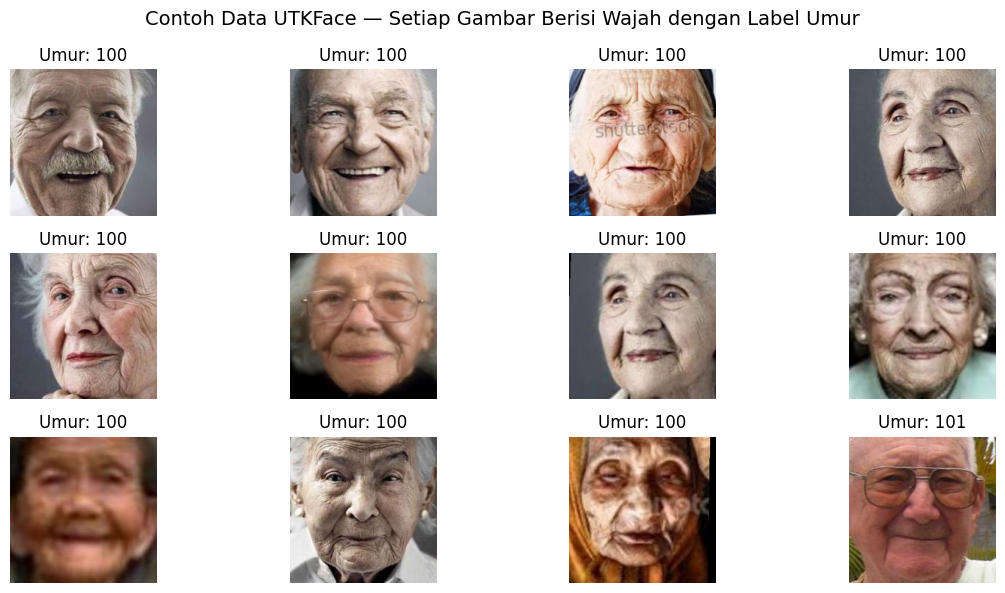

In [70]:
import glob
import os
import matplotlib.pyplot as plt
from PIL import Image

# Ambil 12 gambar acak dari dataset
files = glob.glob('/content/utk/UTKFace/*.jpg')
files = sorted(files)
print(f'Total gambar ditemukan: {len(files)}')

plt.figure(figsize=(12, 6))
for i, f in enumerate(files[:12]):
  # Ambil umur dari nama file
  age = int(os.path.basename(f).split('_')[0])
  img = Image.open(f)
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f'Umur: {age}')
  plt.axis('off')
plt.suptitle(
    'Contoh Data UTKFace — Setiap Gambar Berisi Wajah dengan Label Umur',
    fontsize=14,
)
plt.tight_layout()
plt.show()

**Langkah 5 — Siapkan Dataset untuk Model**

In [71]:
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf


def parse_age_from_name(fp):
  return int(os.path.basename(fp).split('_')[0])


ages = np.array([parse_age_from_name(f) for f in files], dtype=np.float32)
train_files, test_files, y_train, y_test = train_test_split(
    files, ages, test_size=0.2, random_state=42
)

IMG_SIZE = 160


def load_img(fp, label):
  img = tf.io.read_file(fp)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  return img / 255.0, label


train_ds = (
    tf.data.Dataset.from_tensor_slices((train_files, y_train))
    .map(load_img)
    .batch(64)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((test_files, y_test))
    .map(load_img)
    .batch(64)
)
print('✅ Dataset siap dilatih.')

✅ Dataset siap dilatih.


**Langkah 6 — Membangun Model dengan Transfer Learning**

In [72]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models

# Gunakan GPU jika tersedia
print('Hardware:', 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU')

# Buat arsitektur model
base_model = tf.keras.applications.MobileNetV2(
    include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3), weights='imagenet'
)
base_model.trainable = False  # tahap awal: freeze backbone

# Tambahkan head regresi
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x)  # output tunggal: umur
model = tf.keras.Model(inputs, outputs)

# Kompilasi model
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae']
)
model.summary()

Hardware: GPU


Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_21 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_8 (Multiply)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_4 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_4 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_13     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Langkah 7 — Melatih Model (Tahap 1 – Frozen)**

In [78]:
import glob
import os
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf

# 1. Ambil seluruh file gambar UTKFace
files = sorted(glob.glob('/content/utk/UTKFace/*.jpg'))
print(f'Total gambar ditemukan: {len(files)}')

if len(files) == 0:
  print('❌ Dataset kosong! Jalankan ulang perintah unzip di Langkah 3.')
else:
  # 2. Extract label umur
  ages = np.array(
      [int(os.path.basename(f).split('_')[0]) for f in files], dtype=np.float32
  )
  train_files, test_files, y_train, y_test = train_test_split(
      files, ages, test_size=0.2, random_state=42
  )

  IMG_SIZE = 160

  def load_img(fp, label):
    img = tf.io.read_file(fp)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(label, tf.float32)

  # 3. Buat tf.data.Dataset dengan tipe data eksplisit dan prefetch
  train_ds = (
      tf.data.Dataset.from_tensor_slices((train_files, y_train))
      .map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
      .batch(64)
      .prefetch(tf.data.AUTOTUNE)
  )

  test_ds = (
      tf.data.Dataset.from_tensor_slices((test_files, y_test))
      .map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
      .batch(64)
      .prefetch(tf.data.AUTOTUNE)
  )

  print('✅ Dataset siap dilatih.')

Total gambar ditemukan: 23708
✅ Dataset siap dilatih.


**Langkah 8 — Fine-tuning Backbone (Tahap 2)**

Epoch 1/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - loss: 212.2467 - mae: 9.9942 - val_loss: 275.5112 - val_mae: 12.1810 - learning_rate: 1.0000e-04
Epoch 2/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - loss: 70.3494 - mae: 6.2006 - val_loss: 200.4641 - val_mae: 10.2626 - learning_rate: 1.0000e-04
Epoch 3/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - loss: 47.3525 - mae: 5.1441 - val_loss: 175.9163 - val_mae: 9.5706 - learning_rate: 1.0000e-04
Epoch 4/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - loss: 31.3918 - mae: 4.2483 - val_loss: 157.6794 - val_mae: 9.0942 - learning_rate: 1.0000e-04
Epoch 5/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - loss: 22.2118 - mae: 3.5792 - val_loss: 105.4126 - val_mae: 7.3748 - learning_rate: 1.0000e-04


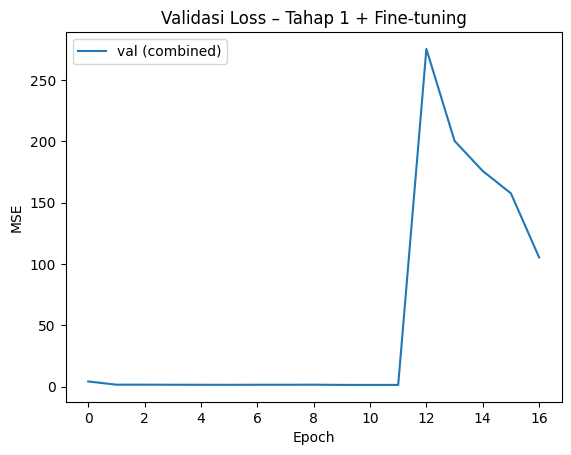

In [79]:
# Aktifkan kembali sebagian layer terakhir untuk fine-tuning
base_model.trainable = True
for layer in base_model.layers[:-30]:
  layer.trainable = False  # beku sebagian besar layer

# Recompile dengan learning rate lebih kecil
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4), loss='mse', metrics=['mae']
)
history_ft = model.fit(
    train_ds, validation_data=test_ds, epochs=5, callbacks=cb, verbose=1
)

# Visualisasi gabungan training dan fine-tuning:
plt.plot(
    history.history['val_loss'] + history_ft.history['val_loss'],
    label='val (combined)',
)
plt.title('Validasi Loss – Tahap 1 + Fine-tuning')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

**Langkah 9 — Evaluasi Akhir (MAE, RMSE, R²)**

MAE = 7.37 tahun
RMSE = 10.27 tahun
R²	= 0.734


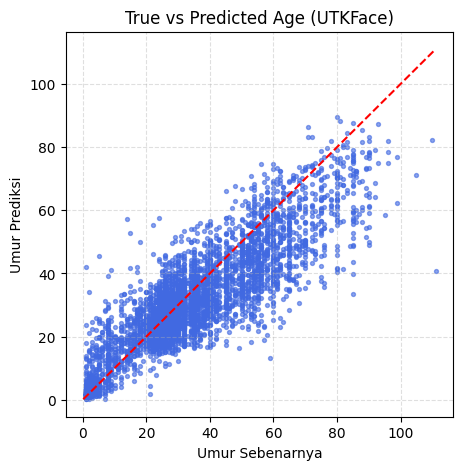

In [80]:
from math import sqrt

y_pred = np.concatenate(
    [model.predict(batch[0], verbose=0).ravel() for batch in test_ds]
)
mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(np.mean((y_test - y_pred) ** 2))
r2 = r2_score(y_test, y_pred)

print(f'MAE = {mae:.2f} tahun')
print(f'RMSE = {rmse:.2f} tahun')
print(f'R²	= {r2:.3f}')

# Plot “umur sebenarnya vs umur prediksi”:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, s=8, alpha=0.6, color='royalblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel('Umur Sebenarnya')
plt.ylabel('Umur Prediksi')
plt.title('True vs Predicted Age (UTKFace)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Langkah 10 — Melihat Contoh Prediksi Nyata

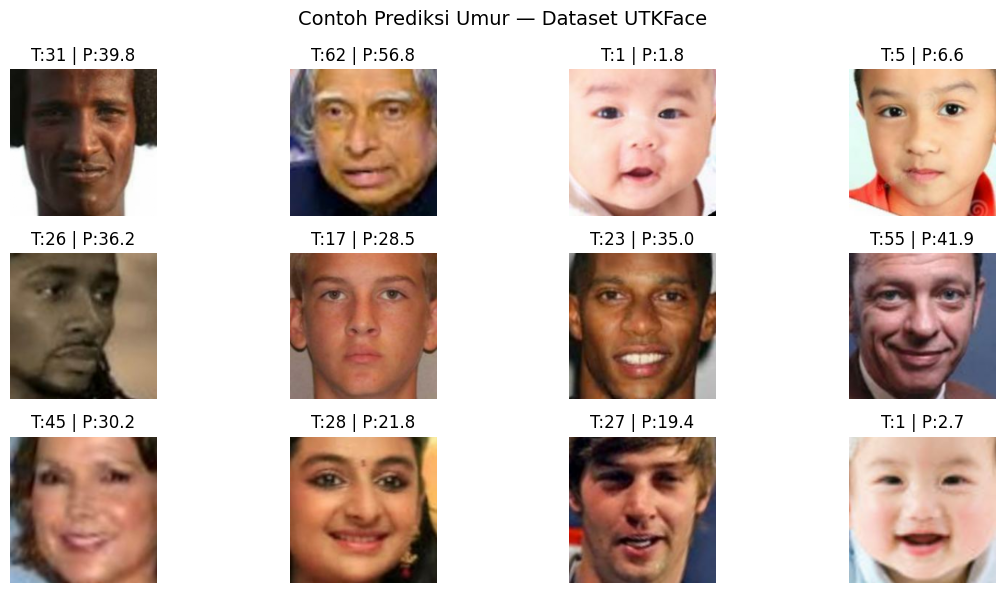

In [81]:
import random

sample_paths = random.sample(test_files, 12)
plt.figure(figsize=(12, 6))
for i, path in enumerate(sample_paths):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0
  true_age = int(os.path.basename(path).split('_')[0])
  pred_age = model.predict(tf.expand_dims(img, 0), verbose=0).ravel()[0]
  plt.subplot(3, 4, i + 1)
  plt.imshow(img.numpy())
  plt.title(f'T:{true_age} | P:{pred_age:.1f}')
  plt.axis('off')
plt.suptitle('Contoh Prediksi Umur — Dataset UTKFace', fontsize=14)
plt.tight_layout()
plt.show()

**TANTANGAN MINI PRAKTIKUM D2**

**1 & 2. Augmentasi Data Ekstra & Learning Rate Scheduler**

In [82]:
# Layer Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomZoom(0.1),
])

# Integrasi Augmentation ke Arsitektur
inputs = tf.keras.Input(shape=(160, 160, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x)

model_aug = tf.keras.Model(inputs, outputs)

# Learning Rate Schedule (Cosine Decay) agar training lebih stabil
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3, decay_steps=1000
)

model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='mse',
    metrics=['mae'],
)

**3. Evaluasi Per Kelompok Umur (Mencari Error Terbesar)**

In [83]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

# 1. Deteksi/Persiapkan y_test jika belum ada di memori
if 'y_test' not in globals():
  y_test = np.array(
      [int(os.path.basename(f).split('_')[0]) for f in test_files],
      dtype=np.float32,
  )

# 2. Pilih model yang tersedia (model_aug, model_age, atau model)
active_model = (
    model_aug
    if 'model_aug' in globals()
    else (model_age if 'model_age' in globals() else model)
)

# 3. Buat prediksi ulang secara otomatis untuk memastikan y_pred_age terisi
print("Sedang melakukan prediksi pada test set...")
y_pred_age = active_model.predict(test_ds, verbose=0).ravel()

# 4. Buat DataFrame evaluasi
df_eval = pd.DataFrame({'True_Age': y_test, 'Pred_Age': y_pred_age})
df_eval['Error_MAE'] = np.abs(df_eval['True_Age'] - df_eval['Pred_Age'])

# 5. Kategorikan umur ke dalam kelompok
bins = [0, 10, 20, 40, 60, 116]
labels = ['0-10', '11-20', '21-40', '41-60', '60+']
df_eval['Age_Group'] = pd.cut(
    df_eval['True_Age'], bins=bins, labels=labels, right=True
)

# 6. Hitung MAE per kelompok umur
mae_per_group = df_eval.groupby('Age_Group', observed=False)[
    'Error_MAE'
].mean()

print("\n--- Rata-rata Error (MAE) per Kelompok Umur ---")
print(mae_per_group)

Sedang melakukan prediksi pada test set...

--- Rata-rata Error (MAE) per Kelompok Umur ---
Age_Group
0-10      3.973508
11-20    16.550049
21-40    29.526377
41-60    51.202515
60+      73.258781
Name: Error_MAE, dtype: float32


**4. Pengujian Wajah Sendiri**

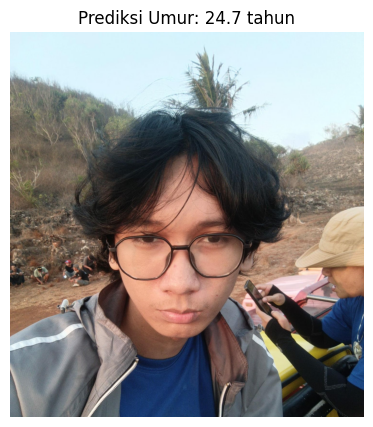

In [84]:
import matplotlib.pyplot as plt
import tensorflow as tf


def test_own_photo(img_path):
  # 1. Read & Preprocess gambar
  img = tf.io.read_file(img_path)
  img = tf.image.decode_jpeg(img, channels=3)
  img_resized = tf.image.resize(img, (160, 160)) / 255.0

  # 2. Paksa memanggil 'model' (model UTKFace Praktikum D2 yang sudah dilatih)
  pred = model.predict(tf.expand_dims(img_resized, 0), verbose=0).ravel()[0]

  # 3. Tampilkan Gambar dan Hasil Prediksi
  plt.figure(figsize=(5, 5))
  plt.imshow(img.numpy().astype('uint8'))
  plt.title(f'Prediksi Umur: {pred:.1f} tahun', fontsize=12)
  plt.axis('off')
  plt.show()


# Panggil fungsi
test_own_photo('foto_saya.jpg')

# **PRAKTIKUM D3 — Menilai “Kepopuleran Hewan Peliharaan” dari Foto**

**Langkah 1 — Menyiapkan Kaggle API**

In [85]:
import os
import shutil

if os.path.exists('kaggle.json'):
  os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
  shutil.copy('kaggle.json', os.path.expanduser('~/.kaggle/kaggle.json'))
  os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)
  !pip -q install kaggle
  print('✅ Kaggle API siap digunakan.')
else:
  print('kaggle.json belum ditemukan. Upload terlebih dahulu.')

✅ Kaggle API siap digunakan.


**Langkah 2 — Mengunduh dan Mengekstrak Dataset**

In [86]:
# Unduh dataset Pawpularity (sekitar 800MB)
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q
!unzip -q /content/petfinder-pawpularity-score.zip -d /content/paw
print('✅ Dataset Pawpularity berhasil diekstrak.')

replace /content/paw/sample_submission.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: A

✅ Dataset Pawpularity berhasil diekstrak.


In [87]:
import os

path = '/content/paw'
if os.path.exists(path):
    print(f"✅ Folder '{path}' exists.")
    contents = os.listdir(path)
    print(f"Contents ({len(contents)} items): {contents[:10]}")
else:
    print(f"❌ Folder '{path}' does not exist. The download or extraction failed.")

✅ Folder '/content/paw' exists.
Contents (5 items): ['train', 'sample_submission.csv', 'test', 'test.csv', 'train.csv']


**Langkah 3 — Melihat Contoh Data**

                                 Id  Subject Focus  Eyes  Face  Near  Action  \
0  0007de18844b0dbbb5e1f607da0606e0              0     1     1     1       0   
1  0009c66b9439883ba2750fb825e1d7db              0     1     1     0       0   
2  0013fd999caf9a3efe1352ca1b0d937e              0     1     1     1       0   
3  0018df346ac9c1d8413cfcc888ca8246              0     1     1     1       0   
4  001dc955e10590d3ca4673f034feeef2              0     0     0     1       0   

   Accessory  Group  Collage  Human  Occlusion  Info  Blur  Pawpularity  \
0          0      1        0      0          0     0     0           63   
1          0      0        0      0          0     0     0           42   
2          0      0        0      1          1     0     0           28   
3          0      0        0      0          0     0     0           15   
4          0      1        0      0          0     0     0           72   

                                                path  
0  /content/p

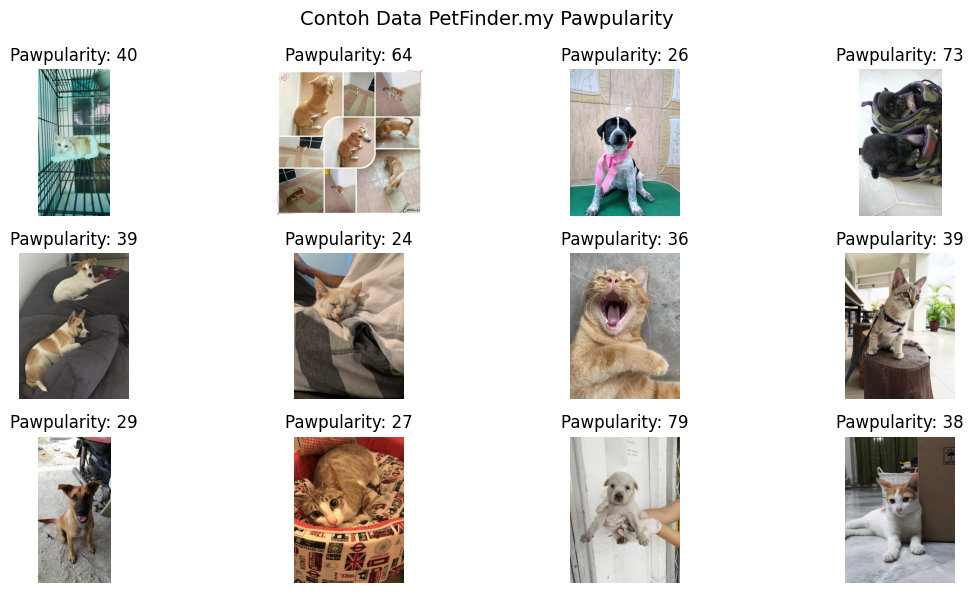

In [3]:
import os
import matplotlib.pyplot as plt

from PIL import Image
import pandas as pd

# Muat CSV
df = pd.read_csv('/content/paw/train.csv')
df['path'] = df['Id'].apply(lambda x: f'/content/paw/train/{x}.jpg')
print(df.head())

# Tampilkan 12 contoh gambar
plt.figure(figsize=(12, 6))
for i, row in enumerate(df.sample(12, random_state=42).itertuples()):
  img = Image.open(row.path)
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f'Pawpularity: {row.Pawpularity}')
  plt.axis('off')
plt.suptitle('Contoh Data PetFinder.my Pawpularity', fontsize=14)
plt.tight_layout()
plt.show()

**Langkah 4 — Persiapan Dataset**

In [4]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

IMG_SIZE = 224
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)


def load_image(path, label):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  img = tf.cast(img, tf.float32) / 255.0
  return img, tf.cast(label, tf.float32)


train_ds = (
    tf.data.Dataset.from_tensor_slices(
        (train_df['path'], train_df['Pawpularity'])
    )
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(4096)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((val_df['path'], val_df['Pawpularity']))
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

print(
    'Dataset siap digunakan —'
    f' {len(train_df)} untuk training, {len(val_df)} untuk validasi.'
)

Dataset siap digunakan — 7929 untuk training, 1983 untuk validasi.


**Langkah 5 — Membangun Model (EfficientNetB0)**

In [5]:
from tensorflow.keras import layers, models

base = tf.keras.applications.EfficientNetB0(
    include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3), weights='imagenet'
)
base.trainable = False  # freeze sementara

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs * 255.0)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(1)(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

**Langkah 6 — Melatih Model**

In [10]:
cb = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5),
]
history = model.fit(
    train_ds, validation_data=val_ds, epochs=10, callbacks=cb, verbose=1
)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 56s 327ms/step - loss: 422.1194 - mae: 15.1825 - val_loss: 422.8661 - val_mae: 15.1093 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 71s 248ms/step - loss: 391.7632 - mae: 14.6828 - val_loss: 400.8574 - val_mae: 14.7864 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 44s 244ms/step - loss: 370.3779 - mae: 14.3023 - val_loss: 385.6089 - val_mae: 14.3669 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 45s 241ms/step - loss: 356.8007 - mae: 14.0114 - val_loss: 377.5060 - val_mae: 14.3829 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 47s 254ms/step - loss: 351.6125 - mae: 13.9390 - val_loss: 370.9044 - val_mae: 14.1159 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 45s 243ms/step - loss: 344.6010 - mae: 13.7787 - val_loss: 371.3530 - val_mae: 14.3671 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 81s 235ms/step - loss: 334.0592 - mae: 13.6007 - val_l

**Langkah 7 — Melihat Proses Belajar**

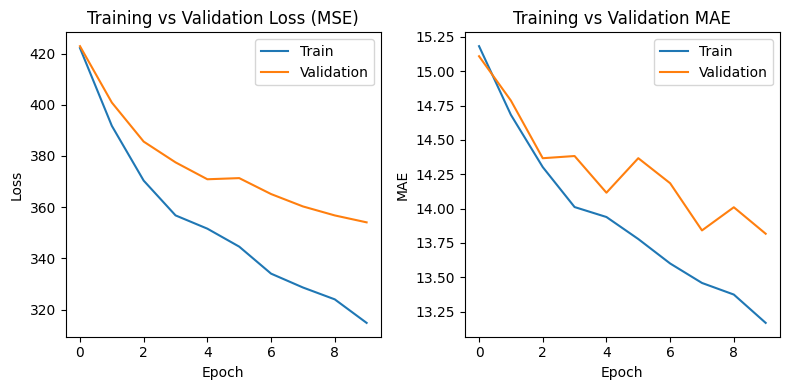

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Training vs Validation Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Validation')
plt.title('Training vs Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

**Langkah 8 — Evaluasi Model**

MAE = 13.82
RMSE = 18.82
R²	= 0.199


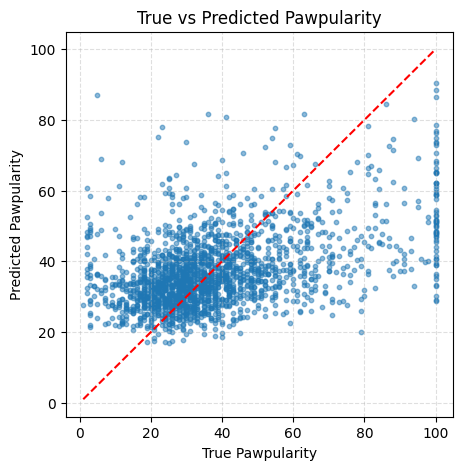

In [12]:
from math import sqrt
from sklearn.metrics import mean_absolute_error, r2_score

import numpy as np

y_true = val_df['Pawpularity'].values.astype(np.float32)
y_pred = np.concatenate(
    [model.predict(batch[0], verbose=0).ravel() for batch in val_ds]
)

mae = mean_absolute_error(y_true, y_pred)
rmse = sqrt(np.mean((y_true - y_pred) ** 2))
r2 = r2_score(y_true, y_pred)

print(f'MAE = {mae:.2f}')
print(f'RMSE = {rmse:.2f}')
print(f'R²	= {r2:.3f}')

# Plot hasil prediksi vs nilai sebenarnya:
plt.figure(figsize=(5, 5))
plt.scatter(y_true, y_pred, s=10, alpha=0.5)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel('True Pawpularity')
plt.ylabel('Predicted Pawpularity')
plt.title('True vs Predicted Pawpularity')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

**Langkah 9 — Melihat Contoh Prediksi**

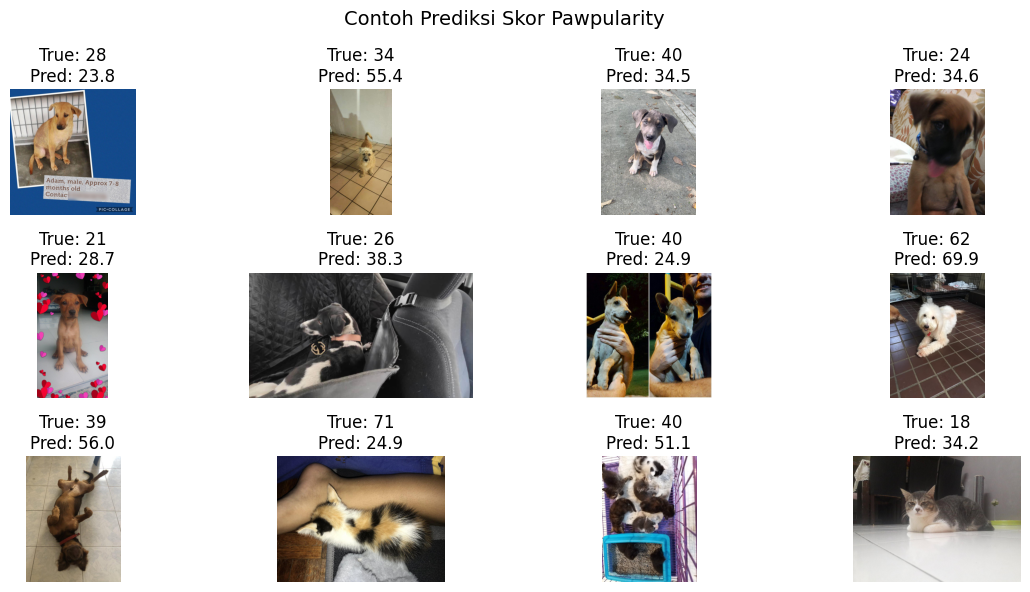

In [13]:
import random
from PIL import Image

sample_rows = val_df.sample(12, random_state=1)
plt.figure(figsize=(12, 6))
for i, row in enumerate(sample_rows.itertuples()):
  img = Image.open(row.path)
  pred = model.predict(
      tf.expand_dims(load_image(row.path, row.Pawpularity)[0], 0), verbose=0
  ).ravel()[0]
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f'True: {row.Pawpularity}\nPred: {pred:.1f}')
  plt.axis('off')
plt.suptitle('Contoh Prediksi Skor Pawpularity', fontsize=14)
plt.tight_layout()
plt.show()

**TANTANGAN MINI PRAKTIKUM D3**

**1 & 2. Menggunakan Model ResNet50 + Augmentasi Data**

In [14]:
from tensorflow.keras import layers, models

# ResNet50 Backbone
base_resnet = tf.keras.applications.ResNet50(
    include_top=False, input_shape=(224, 224, 3), weights='imagenet'
)
base_resnet.trainable = False

data_aug_paw = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomContrast(0.2),
])

inputs_resnet = tf.keras.Input((224, 224, 3))
x = data_aug_paw(inputs_resnet)
x = tf.keras.applications.resnet50.preprocess_input(x * 255.0)
x = base_resnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu')(x)
outputs_resnet = layers.Dense(1)(x)

model_resnet = tf.keras.Model(inputs_resnet, outputs_resnet)
model_resnet.compile(optimizer='adam', loss='mse', metrics=['mae'])

**3. Analisis Bias Spesies (Anjing vs Kucing)**

In [15]:
# Generate prediksi pada validation set terlebih dahulu
y_pred_paw = np.concatenate([model.predict(batch[0], verbose=0).ravel() for batch in val_ds])

# Masukkan hasil prediksi dan hitung MAE Error
val_df['Pred_Pawpularity'] = y_pred_paw
val_df['MAE_Error'] = np.abs(val_df['Pawpularity'] - val_df['Pred_Pawpularity'])

# Tampilkan analisis MAE berdasarkan fitur aksesoris
print("Rata-rata MAE: Tanpa Aksesoris (0) vs Pakai Aksesoris (1)")
print(val_df.groupby('Accessory')['MAE_Error'].mean())

Rata-rata MAE: Tanpa Aksesoris (0) vs Pakai Aksesoris (1)
Accessory
0    13.780444
1    14.313068
Name: MAE_Error, dtype: float64


**4. Integrasi Fitur Non-Visual (Brightness Rata-Rata Citra)**

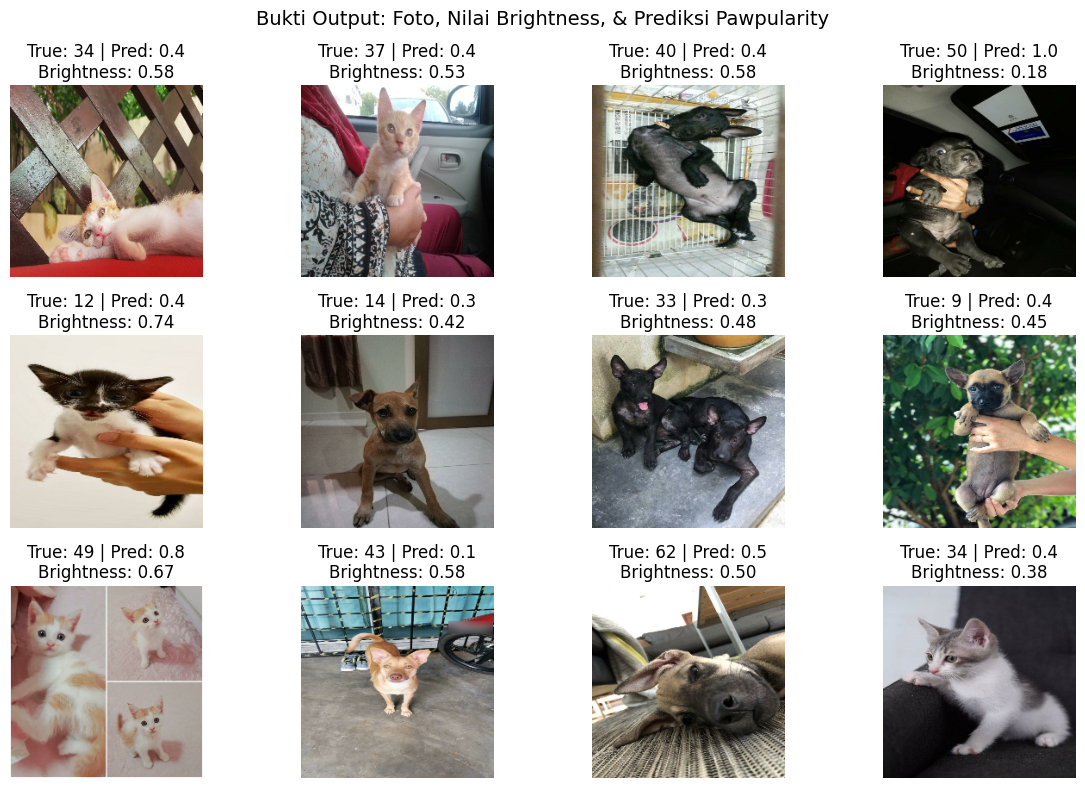

In [19]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = 224


# 1. Definisi Fungsi Load Image Safe
def load_image_safe(path, label):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3, acceptable_fraction=0.8)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  img = tf.cast(img, tf.float32) / 255.0
  return img, tf.cast(label, tf.float32)


# 2. Inisialisasi Arsitektur Multi-Input Model (model_combined)
base_eff = tf.keras.applications.EfficientNetB0(
    include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3), weights='imagenet'
)
base_eff.trainable = False

image_input = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image_input')
bright_input = tf.keras.Input(shape=(1,), name='brightness_input')

# Branch CNN
x_img = tf.keras.applications.efficientnet.preprocess_input(image_input * 255.0)
x_img = base_eff(x_img, training=False)
x_img = layers.GlobalAveragePooling2D()(x_img)

# Penggabungan Fitur Citra + Brightness
concat = layers.concatenate([x_img, bright_input])
dense1 = layers.Dense(256, activation='relu')(concat)
dense1 = layers.Dropout(0.3)(dense1)
output_combined = layers.Dense(1)(dense1)

model_combined = tf.keras.Model(
    inputs=[image_input, bright_input], outputs=output_combined
)
model_combined.compile(optimizer='adam', loss='mse', metrics=['mae'])


# 3. Definisi Fungsi Ekstraksi Brightness
def extract_brightness(image_path):
  img = cv2.imread(image_path)
  hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
  return hsv[:, :, 2].mean() / 255.0


# 4. Ambil Sampel & Ekstraksi Fitur dari Validation Set
val_sample = val_df.sample(12, random_state=42)
val_imgs = []
val_brights = []
val_labels = []

for row in val_sample.itertuples():
  img_tensor, label = load_image_safe(row.path, row.Pawpularity)
  b_val = extract_brightness(row.path)

  val_imgs.append(img_tensor)
  val_brights.append(b_val)
  val_labels.append(label)

X_img_val = np.array(val_imgs)
X_bright_val = np.array(val_brights).reshape(-1, 1)

# 5. Prediksi Menggunakan Multi-Input Model
preds = model_combined.predict(
    {'image_input': X_img_val, 'brightness_input': X_bright_val}, verbose=0
).ravel()

# 6. Tampilkan Visualisasi Foto, Brightness, dan Hasil Prediksi
plt.figure(figsize=(12, 8))
for i in range(12):
  plt.subplot(3, 4, i + 1)
  plt.imshow(X_img_val[i])
  plt.title(
      f'True: {val_labels[i]:.0f} | Pred: {preds[i]:.1f}\nBrightness:'
      f' {X_bright_val[i][0]:.2f}'
  )
  plt.axis('off')

plt.suptitle(
    'Bukti Output: Foto, Nilai Brightness, & Prediksi Pawpularity',
    fontsize=14,
)
plt.tight_layout()
plt.show()